# 01 · Data checks

Loads every dataset collected in phase 1 and checks it before any modelling:

1. **Coverage and gaps**: does each series span the dates we expect, with no missing steps?
2. **Timezones and alignment**: is every timestamp UTC, and on the hour, at 08:00, or at 12:00 New York as intended?
3. **Duplicates**
4. **Bad values**: zero/negative prices, impossible OHLC, absurd IVs, crossed quotes, and big jumps (then inspected by hand)
5. **BTC price vs DVOL**
6. **Summary of problems found**

The checks live in `src/checks.py`, so this notebook stays short. **To refresh:** re-run all cells
(Kernel → Restart & Run All), e.g. after the option-trade pull finishes or more snapshots accumulate.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # project root, so `import config` works

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

import config
from src import checks, visuals          # visuals sets the shared chart style
from src.visuals import BLUE, ORANGE, INK_2

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 60)
print("Run at", pd.Timestamp.now(tz="UTC").strftime("%Y-%m-%d %H:%M UTC"))

Run at 2026-10-02 18:58 UTC


## 1. Coverage and gaps
`missing_steps` counts expected timestamps (given the spacing) that are absent between the first and last row.

In [2]:
checks.coverage()

,rows,start,end,spacing,missing_steps,gap_blocks,largest_gap
dataset,,,,,,,
btc_price_hourly,50354,2021-01-01 00:00:00+00:00,2026-09-30 14:00:00+00:00,h,13,3,5
btc_price_daily,2099,2021-01-01 00:00:00+00:00,2026-09-30 00:00:00+00:00,D,0,0,0
btc_price_0800,2099,2021-01-01 08:00:00+00:00,2026-09-30 08:00:00+00:00,D,0,0,0
btc_index_6h_deribit,8395,2021-01-01 00:00:00+00:00,2026-09-30 12:00:00+00:00,6h,0,0,0
dvol_hourly,48399,2021-03-24 00:00:00+00:00,2026-09-30 14:00:00+00:00,h,0,0,0
dvol_daily,2017,2021-03-24 00:00:00+00:00,2026-09-30 00:00:00+00:00,D,0,0,0
btc_dvol_hourly,48399,2021-03-24 00:00:00+00:00,2026-09-30 14:00:00+00:00,h,0,0,0
btc_dvol_daily,2017,2021-03-24 00:00:00+00:00,2026-09-30 00:00:00+00:00,D,0,0,0
deribit_delivery,2099,2021-01-01 08:00:00+00:00,2026-09-30 08:00:00+00:00,D,0,0,0


The only gaps are in Coinbase hourly prices. Here they are, as blocks:

In [3]:
checks.gap_blocks(checks.load('btc_price_hourly').index, 'h')

,gap_start,missing_steps
0,2023-03-04 18:00:00+00:00,3
1,2025-10-25 16:00:00+00:00,5
2,2026-05-08 02:00:00+00:00,5


Live snapshots: spacing between runs. cron runs every 10 min, so gaps over 15 min mean the Mac was asleep, offline, or a run failed.

In [4]:
checks.snapshot_coverage()

,snapshots,first,last,median_spacing,gaps_over_15min,longest_gap
0,22,2026-09-30 15:46:54+00:00,2026-10-02 16:23:56+00:00,0 days 00:10:00,5,1 days 01:39:59


## 2. Timezones and timestamp alignment
Every datetime column or index in every file type:

In [5]:
tz = checks.timezones()
print('all UTC:', tz['utc'].all())
tz

all UTC: True


,file,column,dtype,utc
0,data/raw/btc_price_hourly.parquet,(index),"datetime64[ms, UTC]",True
1,data/raw/btc_price_daily.parquet,(index),"datetime64[ms, UTC]",True
2,data/raw/btc_price_0800.parquet,(index),"datetime64[ms, UTC]",True
3,data/raw/btc_index_6h_deribit.parquet,(index),"datetime64[ms, UTC]",True
4,data/raw/dvol_hourly.parquet,(index),"datetime64[ms, UTC]",True
5,data/raw/dvol_daily.parquet,(index),"datetime64[ms, UTC]",True
6,data/processed/btc_dvol_hourly.parquet,(index),"datetime64[ms, UTC]",True
7,data/processed/btc_dvol_daily.parquet,(index),"datetime64[ms, UTC]",True
8,data/raw/resolutions/deribit_delivery.parquet,(index),"datetime64[ms, UTC]",True
9,data/raw/resolutions/binance_btcusdt_1m.parquet,(index),"datetime64[ms, UTC]",True


In [6]:
checks.alignment()

,rows,misaligned
check,,
btc_price_hourly on the hour,50354,0
dvol_hourly on the hour,48399,0
daily files at 00:00 UTC,4116,0
btc_price_0800 at 08:00 UTC,2099,0
deribit_delivery at 08:00 UTC,2099,0
binance noon rows at 12:00 New York,2099,0


## 3. Duplicates

In [7]:
checks.duplicates()

,key,rows,duplicates
dataset,,,
btc_price_hourly,timestamp,50354,0
btc_price_daily,timestamp,2099,0
btc_price_0800,timestamp,2099,0
btc_index_6h_deribit,timestamp,8395,0
dvol_hourly,timestamp,48399,0
dvol_daily,timestamp,2017,0
btc_dvol_hourly,timestamp,48399,0
btc_dvol_daily,timestamp,2017,0
deribit_delivery,timestamp,2099,0


## 4. Bad values
### 4a. Price and DVOL time series

In [8]:
checks.bad_values_timeseries()

,dataset,check,rows_flagged
0,btc_price_hourly,price <= 0,0
1,btc_price_hourly,OHLC inconsistent (low > open/close or high < open/close),0
2,btc_price_hourly,|hourly log return| > 10%,2
3,btc_price_hourly,zero-volume hours,0
4,dvol_hourly,DVOL outside 10–250,0
5,dvol_hourly,OHLC inconsistent,0
6,dvol_hourly,|hourly change| > 20 vol points,1
7,btc_price_0800,|spot vs settlement| > 1%,4
8,deribit_delivery,delivery price <= 0,0


Inspect every flagged row, to decide whether it's a data error or a real market move:

In [9]:
h = checks.load("btc_price_hourly")
ret = np.log(h["close"]).diff()
big = ret[ret.abs() > 0.10]
print("Hourly BTC moves > 10%:"); display(h.loc[big.index].assign(log_return=big.round(4)))

d = checks.load("dvol_hourly")
jump = d["close"].diff()
t = jump[jump.abs() > 20].index
print("DVOL hourly jumps > 20 points (with 2h either side):")
for x in t:
    display(d.loc[x - pd.Timedelta("2h"): x + pd.Timedelta("2h")])

at8 = checks.load("btc_price_0800")
print("08:00 Coinbase spot vs Deribit settlement, |diff| > 1%:"); display(at8[at8["diff_pct"].abs() > 1])

Hourly BTC moves > 10%:


,open,high,low,close,volume,log_return
timestamp,,,,,,
2021-01-29 08:00:00+00:00,32322.73,36650.00,32058.57,36344.11,4585.153504,0.1173
2021-05-19 12:00:00+00:00,38682.50,39135.55,31693.32,34632.02,9175.326261,-0.1108


DVOL hourly jumps > 20 points (with 2h either side):


,open,high,low,close
timestamp,,,,
2021-05-17 04:00:00+00:00,129.18,145.61,125.51,140.91
2021-05-17 05:00:00+00:00,140.91,158.55,140.43,158.55
2021-05-17 06:00:00+00:00,158.56,158.72,123.63,125.53
2021-05-17 07:00:00+00:00,125.53,132.50,125.53,132.50
2021-05-17 08:00:00+00:00,132.50,132.97,129.39,129.39


08:00 Coinbase spot vs Deribit settlement, |diff| > 1%:


,delivery_price,spot_close,diff_pct
timestamp,,,
2021-01-30 08:00:00+00:00,33664.46,34051.88,1.150828
2021-03-31 08:00:00+00:00,59038.25,58177.10,-1.458631
2022-02-24 08:00:00+00:00,34966.07,35325.48,1.027882
2022-06-15 08:00:00+00:00,20913.18,20693.82,-1.048908


### 4b. Live snapshots

In [10]:
checks.bad_values_snapshots()

,dataset,check,rows_flagged,rows,share
0,snapshots/deribit,bid > ask (crossed),0,21466,0.0%
1,snapshots/deribit,no bid,896,21466,4.2%
2,snapshots/deribit,no ask,0,21466,0.0%
3,snapshots/deribit,mark_iv <= 0 or > 300,0,21466,0.0%
4,snapshots/deribit,forward_price <= 0,0,21466,0.0%
5,snapshots/deribit,"mark outside [bid, ask]",158,21466,0.7%
6,snapshots/predmarkets,bid > ask (crossed),0,15766,0.0%
7,snapshots/predmarkets,"price outside [0, 1]",0,15766,0.0%
8,snapshots/predmarkets,no two-sided quote,10360,15766,65.7%
9,snapshots/predmarkets,spread > 10¢,80,15766,0.5%


In [11]:
dd = checks.load_snapshots("deribit")
out = dd[(dd["mark_price"] < dd["bid"]) | (dd["mark_price"] > dd["ask"])]
gap = np.maximum(dd["bid"] - dd["mark_price"], dd["mark_price"] - dd["ask"]).loc[out.index]
print(f"Deribit mark outside [bid, ask]: {len(out)} rows; largest distance {gap.max():.6f} BTC (tick = 0.0001)")

p = checks.load_snapshots("predmarkets")
by_venue = p.assign(
    zero_volume=p["volume"].fillna(0) <= 0,
    one_sided=p["yes_bid"].isna() | p["yes_ask"].isna(),
).groupby("venue")[["zero_volume", "one_sided"]].mean()
by_venue.style.format("{:.0%}")

Deribit mark outside [bid, ask]: 158 rows; largest distance 0.000221 BTC (tick = 0.0001)


,zero_volume,one_sided
venue,,
kalshi,69%,82%
polymarket,26%,18%


### 4c. Historical option trades (per month)
Aggregated file by file. The pull may still be running, so check the month range.

In [12]:
tr = checks.bad_values_trades()
print(f"{len(tr)} months ({tr.index[0]} to {tr.index[-1]}), {tr['trades'].sum():,} trades")
tr

69 months (2021-01 to 2026-09), 22,723,314 trades


,trades,dup_trade_id,price<=0,iv=0,iv>=300,neg_dte,index<=0,block,combo,tz_utc
month,,,,,,,,,,
2021-01,397694,0,0,2009,746,0,0,1401,0,True
2021-02,256303,0,0,1048,303,0,0,1277,0,True
2021-03,284257,0,0,802,220,0,0,1864,0,True
2021-04,335317,0,0,1176,661,0,0,1826,0,True
2021-05,351533,0,0,1464,892,0,0,1910,0,True
...,...,...,...,...,...,...,...,...,...,...
2026-05,279026,0,0,892,69,0,0,3967,4902,True
2026-06,373832,0,0,1485,306,0,0,5433,6087,True
2026-07,280432,0,0,750,37,6,0,4140,3798,True


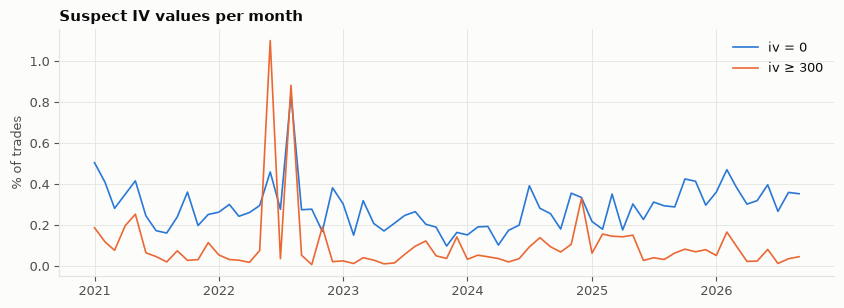

In [13]:
share = tr[["iv=0", "iv>=300", "block", "combo"]].div(tr["trades"], axis=0) * 100
fig, ax = plt.subplots(figsize=(10, 3.2))
ax.plot(pd.to_datetime(share.index), share["iv=0"], color=BLUE, label="iv = 0")
ax.plot(pd.to_datetime(share.index), share["iv>=300"], color=ORANGE, label="iv ≥ 300")
ax.set_ylabel("% of trades"); ax.legend(loc="upper right")
ax.set_title("Suspect IV values per month")
plt.show()

## 5. BTC price vs DVOL
Two panels on one time axis (their scales are unrelated, so no dual axis), then daily BTC returns
against same-day DVOL changes.

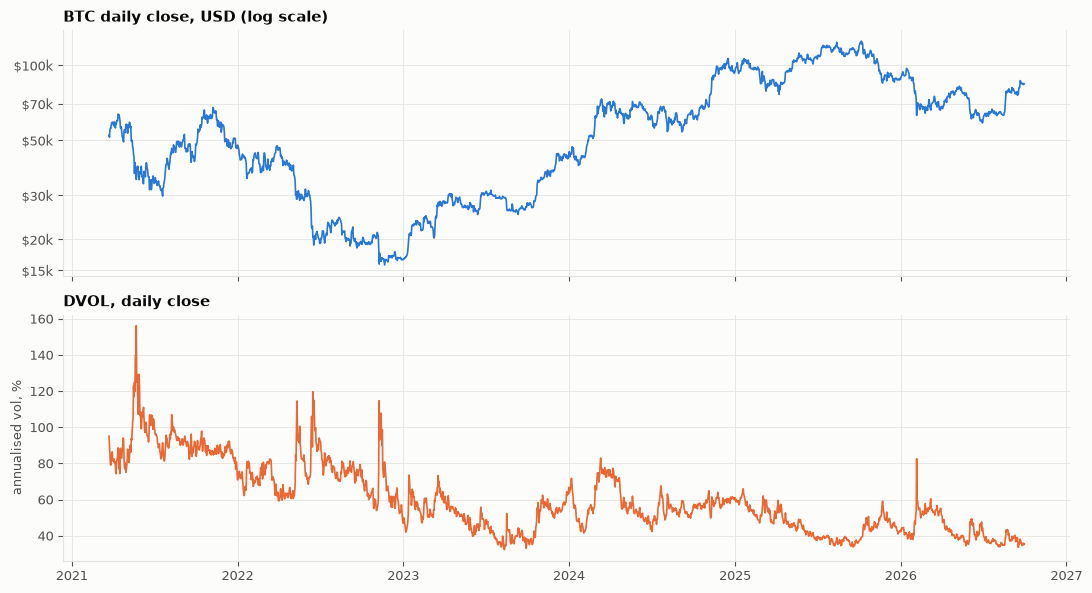

In [14]:
m = pd.read_parquet(config.DATA_PROCESSED / "btc_dvol_daily.parquet")
fig, (a1, a2) = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
a1.plot(m.index, m["btc_close"], color=BLUE); visuals.usd_log_axis(a1)
a1.set_title("BTC daily close, USD (log scale)")
a2.plot(m.index, m["dvol_close"], color=ORANGE)
a2.set_ylabel("annualised vol, %"); a2.set_title("DVOL, daily close")
a2.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout(); plt.show()

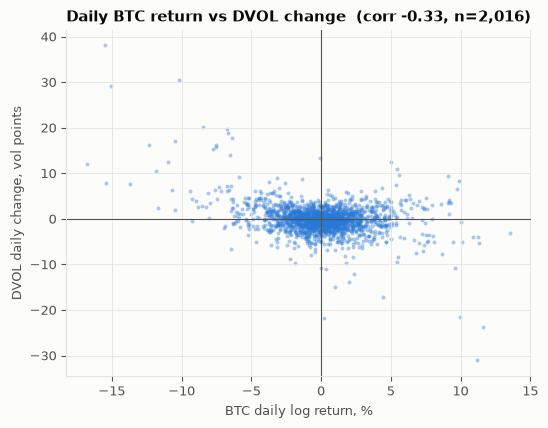

Days BTC fell >5%: DVOL change median +3.2 pts (n=83)
Days BTC rose >5%: DVOL change median +0.2 pts (n=78)


In [15]:
x = pd.DataFrame({"btc_ret_%": np.log(m["btc_close"]).diff() * 100,
                  "dvol_chg": m["dvol_close"].diff()}).dropna()
corr = x.corr().iloc[0, 1]
fig, ax = plt.subplots(figsize=(6, 4.5))
ax.scatter(x["btc_ret_%"], x["dvol_chg"], s=8, alpha=0.4, color=BLUE, linewidths=0)
ax.axhline(0, color=INK_2, lw=0.8); ax.axvline(0, color=INK_2, lw=0.8)
ax.set_xlabel("BTC daily log return, %"); ax.set_ylabel("DVOL daily change, vol points")
ax.set_title(f"Daily BTC return vs DVOL change  (corr {corr:+.2f}, n={len(x):,})")
plt.show()
up, down = x[x["btc_ret_%"] > 5], x[x["btc_ret_%"] < -5]
print(f"Days BTC fell >5%: DVOL change median {down['dvol_chg'].median():+.1f} pts (n={len(down)})")
print(f"Days BTC rose >5%: DVOL change median {up['dvol_chg'].median():+.1f} pts (n={len(up)})")

## 6. Summary of problems found
Everything flagged by the checks above, in one table:

In [16]:
checks.problems()

,dataset,issue,count,detail
0,btc_price_hourly,gaps,13,"3 blocks, largest 5 steps"
1,snapshots,gaps > 15 min,5,longest 1 days 01:39:59
2,btc_price_hourly,|hourly log return| > 10%,2,
3,dvol_hourly,|hourly change| > 20 vol points,1,
4,btc_price_0800,|spot vs settlement| > 1%,4,
5,snapshots/deribit,no bid,896,4.2% of rows
6,snapshots/deribit,"mark outside [bid, ask]",158,0.7% of rows
7,snapshots/predmarkets,no two-sided quote,10360,65.7% of rows
8,snapshots/predmarkets,spread > 10¢,80,0.5% of rows
9,snapshots/predmarkets,zero volume,9137,58.0% of rows


### Interpretation (updated 2026-10-02: all 69 trade months, 22.7M trades; 22 live snapshots)

**No data needs correcting. Every flag is either a real market event or a filtering rule for the modelling phase.**

| Area | Finding | Verdict / action |
|---|---|---|
| Live snapshots | 22 snapshots over 3 days: **5 gaps > 15 min, longest 25.7 h**, because the Mac was asleep (cron stopgap). | Expected; fixed by moving to a VPS. |
| Coverage | All series complete, except **13 missing Coinbase hours** in 3 blocks (2023-03-04, 2025-10-25, 2026-05-08: exchange outages). DVOL starts 2021-03-24 (its launch). | Leave as NaN; don't forward-fill raw data. Use the Deribit 6h index or settlement prices if one of those hours is ever needed. |
| Timezones | Every timestamp in every file is tz-aware **UTC**, and all sit exactly on the hour, at 00:00, at 08:00, or at 12:00 New York (DST handled: 16:00 UTC in summer, 17:00 UTC in winter). | OK. (Some `expiry`/snapshot columns are stored in µs rather than ms. Harmless: pandas joins across units.) |
| Duplicates | None anywhere (time series, trade ids, snapshot rows, resolutions). | OK. |
| BTC vs DVOL | Daily correlation −0.33. On days BTC fell > 5%, DVOL rose a median 3.2 pts; on days it rose > 5%, +0.2 pts. | Expected: vol rises after sell-offs. Sanity check on the data, not a problem. |
| Big BTC moves | 2 hourly moves > 10%: **2021-01-29** (+11.7%, Musk adds #bitcoin to Twitter bio) and **2021-05-19** (−11%, May 2021 crash). | Real. Keep. |
| DVOL jump | 33-point drop in one hour on **2021-05-17**, right after a spike to 158 (crash week). | Plausible (a 1-hour spike that reverses) but not verifiable against a second source. Keep; be aware it's there. |
| 08:00 spot vs settlement | 4 days with |diff| > 1%, all very volatile days. Settlement is a 30-min average, spot is one instant. | Expected. Use `delivery_price` as the outcome, never spot. |
| Deribit snapshots | 3.5% of options have no bid (deep OTM, worthless); 0.7% have mark outside bid/ask by at most ~2 ticks (0.0002 BTC). | Rounding/timing, not an error. Filter no-bid rows when fitting. |
| Prediction markets | **Kalshi: 66% of strike rows have zero volume, 43% one-sided.** Polymarket: 21% / 27%. Only 0.4% have spreads > 10¢. No crossed quotes, no prices outside [0, 1], and no cases where P(BTC > K) rises with K. | Liquidity is concentrated near the money. In analysis, use only two-sided quotes with volume and a spread cap. |
| Option trades | **iv = 0 on 0.29%** of 22.7M trades, **iv ≥ 300 on 0.11%**, both spiking in **Jun–Aug 2022** (Celsius/3AC crash; iv ≥ 300 hit 1.1% of trades). Of iv = 0 rows, 4% are block/combo (11% in 2026 as combos grew). No duplicate ids, no zero prices. **6 trades** have negative time to expiry: all 15 Jul 2026, 2–2.5 min after the 08:00 expiry (a delayed expiry that day). | Excluded in phase 3 cleaning (with combo legs and < 1 day to expiry, which also removes the 6 post-expiry trades). |

**To re-check** once the trade pull finishes and snapshots accumulate: re-run all cells. Section 4c and the summary table update automatically; the interpretation table above is a dated note.